# 9. ChemNet, 1995: where this all started

**What you will learn:** what Dmitry Kireev's ChemNet did in 1995, why its
per-node message aggregation prefigures modern message passing, and — in code —
how a small modern reconstruction of the idea behaves on molecules.

## The paper

> **Kireev, D. B.** "ChemNet: A Novel Neural Network Based Method for
> Graph/Property Mapping." *J. Chem. Inf. Comput. Sci.* **1995**, *35* (2),
> 175-180. DOI: [10.1021/ci00024a001](https://doi.org/10.1021/ci00024a001)

ChemNet was **among the first** neural networks to map a molecular graph
*directly* into the architecture of the network, instead of first compressing
the molecule into a fixed vector of descriptors. Each non-hydrogen atom got its
own neuron, and the connection weights between neurons were **tied to the
topological distance** between the corresponding atoms: every pair of atoms
three bonds apart shared one weight, every pair two bonds apart shared another.

That is weight sharing over graph structure — the same argument modern graph
convolutions rest on, written down in 1995.

### On priority, carefully

The University of Missouri Chemistry department's page for Prof. Kireev
describes ChemNet as *"the first published instance of a graph-convolutional
network architecture"*
([chemistry.missouri.edu/people/kireev](https://chemistry.missouri.edu/people/kireev)).
That claim is theirs, and it is attributed here rather than asserted.

Kireev himself has been more cautious in public: writing in 2025 he said it
*"might have been among the first"*, and described how, in a single layer,
messages were passed to a node from all other nodes in a Transformer-like
fashion. **This notebook follows his framing**, which is also the more
defensible one — and, as it happens, the more interesting one, because the
"attend to every atom at once, weighted by graph distance" pattern is precisely
what graph transformers rediscovered twenty-five years later.

### Contemporaneous related work

ChemNet was not alone. Two other architectures of the same era also built the
network *from* the molecular graph:

* **Baskin, I. I.; Palyulin, V. A.; Zefirov, N. S.** "A Neural Device for
  Searching Direct Correlations between Structures and Properties of Chemical
  Compounds." *J. Chem. Inf. Comput. Sci.* **1997**, *37* (4), 715-721. DOI:
  [10.1021/ci940128y](https://doi.org/10.1021/ci940128y) — a network whose
  architecture guarantees invariance to atom renumbering, built by analogy with
  biological vision systems.
* **Ivanciuc, O.** — **MolNet**, a multilayer perceptron in which each
  non-hydrogen atom has a neuron in the input and hidden layers, the
  input-hidden connections encode the topological distance matrix, and the
  hidden-output connections are grouped by atom type. Reviewed in Ivanciuc, O.
  "Quantitative Structure-Activity Relationships (QSAR) with the MolNet
  Molecular Graph Machine." *Curr. Comput.-Aided Drug Des.* **2011**, *6* (2),
  261-268. DOI:
  [10.2174/1574893611106020261](https://doi.org/10.2174/1574893611106020261).

Ivanciuc's review chapter "Molecular Graph Descriptors Used in Neural Network
Models" (in *Topological Indices and Related Descriptors in QSAR and QSPR*,
Devillers, J.; Balaban, A. T., Eds.; Gordon & Breach, 1999, pp. 697-777)
discusses all three together as networks generated from the molecular graph —
the Baskin-Palyulin-Zefirov neural device, Kireev's ChemNet, and MolNet. If you
want the primary-source history of this idea, that chapter is where to start.

The modern lineage picks up with Duvenaud et al.'s neural fingerprints
(NeurIPS 2015, DOI:
[10.48550/arXiv.1509.09292](https://doi.org/10.48550/arXiv.1509.09292)) and
Gilmer et al.'s MPNN framework (ICML 2017, DOI:
[10.48550/arXiv.1704.01212](https://doi.org/10.48550/arXiv.1704.01212)), which
unified everything notebook 04 covers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as Fn

from mgnn import features as F
from mgnn.chemnet import (
    ChemNetLayer,
    ChemNetModel,
    distance_buckets,
    topological_distance_matrix,
)
from mgnn.data import WORKED_TASKS, load_tox21_graphs
from mgnn.layers import gcn_normalised_adjacency
from mgnn.splits import scaffold_split
from mgnn.train import set_seed
from mgnn.viz import draw_molecule_with_indices, show
from sklearn.metrics import average_precision_score, roc_auc_score

np.set_printoptions(precision=3, suppress=True, linewidth=130)
plt.rcParams["figure.dpi"] = 110
torch.set_num_threads(4)
set_seed(0)

## 9.1 The topological distance matrix

Modern message passing is indexed by the **adjacency** matrix: who is one bond
away. ChemNet was indexed by the **distance** matrix: how many bonds away
everything is. The adjacency matrix is the $d = 1$ shell of the distance
matrix, so the 1995 formulation is strictly the more general one.

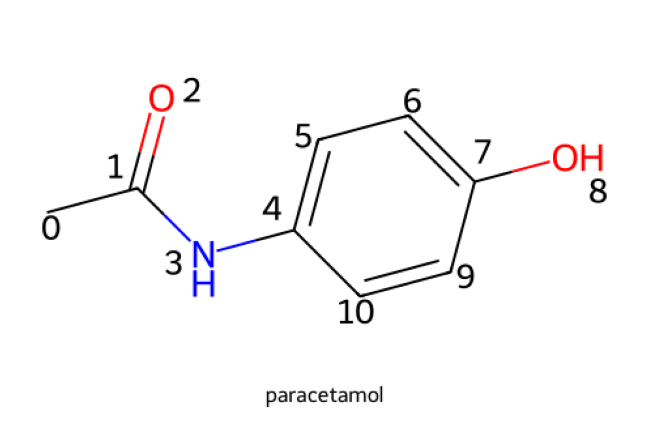

,C0,C1,O2,N3,C4,C5,C6,C7,O8,C9,C10
C0,0,1,2,2,3,4,5,6,7,5,4
C1,1,0,1,1,2,3,4,5,6,4,3
O2,2,1,0,2,3,4,5,6,7,5,4
N3,2,1,2,0,1,2,3,4,5,3,2
C4,3,2,3,1,0,1,2,3,4,2,1
C5,4,3,4,2,1,0,1,2,3,3,2
C6,5,4,5,3,2,1,0,1,2,2,3
C7,6,5,6,4,3,2,1,0,1,1,2
O8,7,6,7,5,4,3,2,1,0,2,3
C9,5,4,5,3,2,3,2,1,2,0,1


maximum distance (the graph diameter): 7 bonds


In [2]:
smiles = "CC(=O)Nc1ccc(O)cc1"          # paracetamol again, for continuity
graph = F.smiles_to_graph(smiles)
labels = [f"{s}{i}" for i, s in enumerate(graph.atom_symbols())]
show(draw_molecule_with_indices(smiles, size=(480, 320), legend="paracetamol"))
plt.show()

D = topological_distance_matrix(smiles)
display(pd.DataFrame(D, index=labels, columns=labels))
print("maximum distance (the graph diameter):", int(D.max()), "bonds")

the adjacency matrix is exactly the d = 1 shell of the distance matrix: True


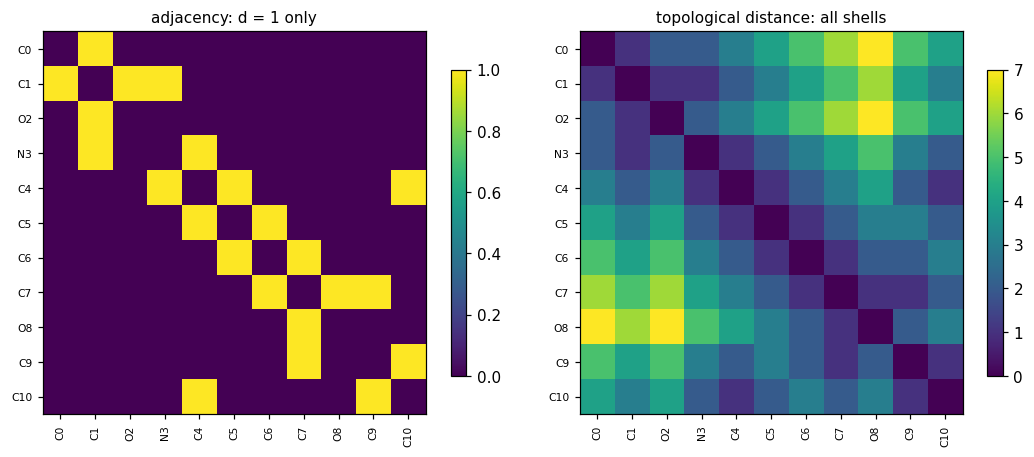

In [3]:
A = F.adjacency_matrix(graph)
print("the adjacency matrix is exactly the d = 1 shell of the distance matrix:",
      bool(np.array_equal(A.astype(int), (D == 1).astype(int))))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (M, title) in zip(axes, [(A, "adjacency: d = 1 only"),
                                 (D, "topological distance: all shells")]):
    im = ax.imshow(M, cmap="viridis")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 9.2 Weight sharing by distance shell

`mgnn.chemnet.ChemNetLayer` implements the idea in modern form:

$$ h'_i = b + \sum_{d=0}^{D} \; \sum_{j \,:\, \mathrm{dist}(i,j) = d} W_d \, h_j $$

One weight matrix per distance shell, reused for every atom pair at that
distance, in every molecule. Distances beyond a cap — and atoms in a different
fragment, which have no finite distance at all — fall into one overflow bucket,
which keeps the parameter count fixed regardless of molecule size. That cap is
the same device a relative-position bias uses in a transformer.

In [4]:
MAX_D = 5
buckets = distance_buckets(D, max_distance=MAX_D)
display(pd.DataFrame(buckets.numpy(), index=labels, columns=labels))
print(f"bucket values run 0..{MAX_D + 1}; bucket {MAX_D + 1} holds "
      f'"further than {MAX_D} bonds" and "different fragment"')

layer = ChemNetLayer(F.ATOM_FEATURE_DIM, 16, max_distance=MAX_D)
out = layer(graph.x, buckets)
print("\nChemNetLayer out:", tuple(out.shape))
print("weight tensor:", tuple(layer.weight.shape),
      "= one (in x out) matrix per distance bucket")
print("parameters:", sum(p.numel() for p in layer.parameters()))

,C0,C1,O2,N3,C4,C5,C6,C7,O8,C9,C10
C0,0,1,2,2,3,4,5,6,6,5,4
C1,1,0,1,1,2,3,4,5,6,4,3
O2,2,1,0,2,3,4,5,6,6,5,4
N3,2,1,2,0,1,2,3,4,5,3,2
C4,3,2,3,1,0,1,2,3,4,2,1
C5,4,3,4,2,1,0,1,2,3,3,2
C6,5,4,5,3,2,1,0,1,2,2,3
C7,6,5,6,4,3,2,1,0,1,1,2
O8,6,6,6,5,4,3,2,1,0,2,3
C9,5,4,5,3,2,3,2,1,2,0,1


bucket values run 0..6; bucket 6 holds "further than 5 bonds" and "different fragment"



ChemNetLayer out: (11, 16)
weight tensor: (7, 41, 16) = one (in x out) matrix per distance bucket
parameters: 4608


### A salt shows what the overflow bucket is for

In [5]:
salt = "CC(=O)[O-].[Na+]"
D_salt = topological_distance_matrix(salt)
print("raw distance matrix (-1 marks 'no path between fragments'):")
print(D_salt)
print("\nbucketed:")
print(distance_buckets(D_salt, max_distance=MAX_D).numpy())

raw distance matrix (-1 marks 'no path between fragments'):
[[ 0  1  2  2 -1]
 [ 1  0  1  1 -1]
 [ 2  1  0  2 -1]
 [ 2  1  2  0 -1]
 [-1 -1 -1 -1  0]]

bucketed:
[[0 1 2 2 6]
 [1 0 1 1 6]
 [2 1 0 2 6]
 [2 1 2 0 6]
 [6 6 6 6 0]]


## 9.3 The thing a modern GNN cannot do in one layer

This is the heart of it. In a GCN, information travels one bond per layer
(notebook 02): after one layer an atom knows only about its neighbours. A
ChemNet layer reaches **every atom at once**.

The demonstration: put a signal on one end of octane and apply a single layer
of each.

In [6]:
octane = F.smiles_to_graph("CCCCCCCC")
D_oct = topological_distance_matrix("CCCCCCCC")
buckets_oct = distance_buckets(D_oct, max_distance=10)

x = torch.zeros_like(octane.x)
x[7] = octane.x[7]                       # only the far atom carries anything

chem_layer = ChemNetLayer(F.ATOM_FEATURE_DIM, 4, max_distance=10, bias=False)
chem_out = chem_layer(x, buckets_oct)

A_hat = gcn_normalised_adjacency(octane.edge_index, octane.num_nodes)
gcn_out = A_hat @ (x @ torch.randn(F.ATOM_FEATURE_DIM, 4))

comparison = pd.DataFrame({
    "atom": [f"C{i}" for i in range(8)],
    "distance from C7": D_oct[7],
    "|ChemNet output| after 1 layer": chem_out.abs().sum(dim=1).detach().numpy(),
    "|GCN output| after 1 layer": gcn_out.abs().sum(dim=1).detach().numpy(),
}).set_index("atom")
display(comparison.style.format({"|ChemNet output| after 1 layer": "{:.4f}",
                                 "|GCN output| after 1 layer": "{:.4f}"}))
print("The GCN moved the signal exactly one bond (only C6 and C7 are non-zero).")
print("The ChemNet layer delivered it to all eight atoms, with a different")
print("learned weight matrix for each distance -- so 'far' is not the same as")
print("'near', but neither is it unreachable.")

,distance from C7,|ChemNet output| after 1 layer,|GCN output| after 1 layer
atom,,,
C0,7,1.6937,0.0000
C1,6,1.8766,0.0000
C2,5,1.6880,0.0000
C3,4,1.8477,0.0000
C4,3,1.0943,0.0000
C5,2,1.1697,0.0000
C6,1,1.2086,2.1989
C7,0,2.0683,2.6931


The GCN moved the signal exactly one bond (only C6 and C7 are non-zero).
The ChemNet layer delivered it to all eight atoms, with a different
learned weight matrix for each distance -- so 'far' is not the same as
'near', but neither is it unreachable.


## 9.4 GCN as a special case

Zero out every shell past $d = 1$ and a ChemNet layer collapses to a one-hop
graph convolution. The reachability patterns become identical: this is what it
means to say the 1995 formulation generalises the 2017 one.

In [7]:
restricted = ChemNetLayer(F.ATOM_FEATURE_DIM, 6, max_distance=MAX_D, bias=False)
with torch.no_grad():
    for d in range(2, restricted.n_buckets):
        restricted.weight[d].zero_()
    restricted.weight[0].copy_(restricted.weight[1])   # tie self to neighbour

reach_chemnet = ((buckets == 0) | (buckets == 1))
reach_gcn = (gcn_normalised_adjacency(graph.edge_index, graph.num_nodes) > 0)
print("one-hop ChemNet and GCN reach exactly the same atom pairs:",
      bool(torch.equal(reach_chemnet, reach_gcn)))
print("\nand the restricted layer still runs:",
      tuple(restricted(graph.x, buckets).shape))

one-hop ChemNet and GCN reach exactly the same atom pairs: True

and the restricted layer still runs: (11, 6)


## 9.5 Does the reconstruction learn anything?

A small ChemNet-style model trained on the same Tox21 scaffold split used
elsewhere in this series, on **SR-MMP** only, with a subset of the training
data. The point is to show the architecture trains and produces a signal — not
to compete with notebook 07's model, which has the advantage of a modern layer,
more data and more epochs.

Note the cost: all-pairs aggregation is $O(N^2)$ per molecule and this
implementation loops over molecules, which is why the subset is small. That
cost is also, historically, a good part of why the one-hop formulation won.

In [8]:
ds = load_tox21_graphs(tasks=WORKED_TASKS, verbose=False)
train_idx, valid_idx, test_idx = scaffold_split(ds.smiles, 0.8, 0.1, 0.1)
SR = WORKED_TASKS.index("SR-MMP")


def prepare(indices, limit):
    """Keep molecules that were actually measured in SR-MMP, up to `limit`."""
    xs, bks, ys = [], [], []
    for i in indices:
        if not ds.y_mask[i, SR]:
            continue
        g = ds.graphs[i]
        if g.num_nodes > 40:          # the N^2 cost bites on big molecules
            continue
        try:
            D_i = topological_distance_matrix(g.smiles)
        except ValueError:
            continue
        xs.append(g.x)
        bks.append(distance_buckets(D_i, MAX_D))
        ys.append(float(ds.y[i, SR]))
        if len(xs) >= limit:
            break
    return xs, bks, torch.tensor(ys).unsqueeze(1)


x_tr, b_tr, y_tr = prepare(train_idx, 900)
x_te, b_te, y_te = prepare(test_idx, 300)
print(f"ChemNet training set: {len(x_tr)} molecules "
      f"({int(y_tr.sum())} active), test set: {len(x_te)} ({int(y_te.sum())} active)")

ChemNet training set: 900 molecules (122 active), test set: 300 (57 active)


In [9]:
set_seed(0)
chemnet = ChemNetModel(n_tasks=1, hidden_dim=32, n_layers=2, max_distance=MAX_D,
                       dropout=0.1)
print("parameters:", sum(p.numel() for p in chemnet.parameters()))

opt = torch.optim.Adam(chemnet.parameters(), lr=3e-3)
pos_weight = torch.tensor([3.0])
batch_size = 32
losses = []

for epoch in range(1, 13):
    chemnet.train()
    order = torch.randperm(len(x_tr))
    total, n_batches = 0.0, 0
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size].tolist()
        logits = chemnet([x_tr[i] for i in idx], [b_tr[i] for i in idx])
        loss = Fn.binary_cross_entropy_with_logits(
            logits, y_tr[idx], pos_weight=pos_weight)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(chemnet.parameters(), 5.0)
        opt.step()
        total += float(loss)
        n_batches += 1
    losses.append(total / n_batches)
    print(f"  epoch {epoch:2d}  loss {losses[-1]:.4f}", flush=True)

parameters: 17505


  epoch  1  loss 0.8714


  epoch  2  loss 0.6016


  epoch  3  loss 0.5956


  epoch  4  loss 0.5017


  epoch  5  loss 0.4789


... (3 outputs left out)

  epoch  9  loss 0.3289


  epoch 10  loss 0.2561


  epoch 11  loss 0.3128


  epoch 12  loss 0.2508


ChemNet-style model, SR-MMP, scaffold-split test subset (300 molecules, 57 active):
  ROC-AUC 0.710
  PR-AUC  0.333   (base rate 0.190)


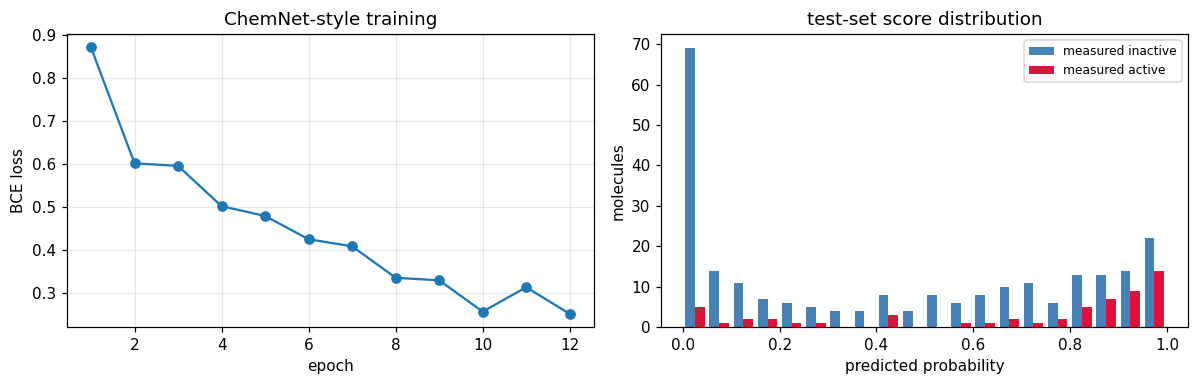

In [10]:
chemnet.eval()
with torch.no_grad():
    probs = torch.sigmoid(chemnet(x_te, b_te)).numpy().ravel()
y_true = y_te.numpy().ravel()

chem_roc = roc_auc_score(y_true, probs)
chem_pr = average_precision_score(y_true, probs)
print(f"ChemNet-style model, SR-MMP, scaffold-split test subset "
      f"({len(y_true)} molecules, {int(y_true.sum())} active):")
print(f"  ROC-AUC {chem_roc:.3f}")
print(f"  PR-AUC  {chem_pr:.3f}   (base rate {y_true.mean():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(range(1, len(losses) + 1), losses, marker="o")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss"); axes[0].set_title("ChemNet-style training")
axes[0].grid(alpha=0.3)
axes[1].hist([probs[y_true == 0], probs[y_true == 1]], bins=20, stacked=False,
             label=["measured inactive", "measured active"], color=["steelblue", "crimson"])
axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("molecules")
axes[1].set_title("test-set score distribution"); axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

A model with a few thousand parameters, trained for a few minutes on under a
thousand molecules, using an architecture published in 1995, separates actives
from inactives on a held-out scaffold split. That is the point of the exercise:
the *idea* was sound and complete thirty years ago. What arrived later was
scale, automatic differentiation, GPUs, and the one-hop simplification that
made it cheap.

## 9.6 What was already there in 1995, and what was not

| idea | in ChemNet (1995) | in a modern GNN |
|---|---|---|
| network built from the molecular graph | yes | yes |
| weights shared across atom pairs by structure | yes, by topological distance | yes, by adjacency |
| permutation invariance guaranteed by construction | yes | yes |
| one layer sees the whole molecule | yes | no (needs depth, or a transformer) |
| learned atom features | limited | yes, high-dimensional embeddings |
| depth | shallow | 3-5 layers typical |
| trained by backpropagation | yes | yes |
| GPU-scale data | no | yes |

The row that matters is the fourth. Modern message passing *gave something up*
— global reach in a single layer — in exchange for cheap local computation, and
then spent two decades inventing ways to get it back: virtual nodes, jumping
knowledge, and ultimately graph transformers with distance-biased attention,
which is close to where ChemNet started.

## Acknowledgement

With thanks to **Prof. Dmitri Kireev**, whose 1995 ChemNet paper is the
starting point for this notebook and for much of what the rest of this
repository teaches. Any errors in characterising that work are mine.

## What to take away

* ChemNet mapped the molecular graph into the network itself and shared
  weights by topological distance — graph convolution's central idea, in 1995.
* It is fair to call it **among the first** such architectures; the stronger
  "first published instance" claim comes from the University of Missouri's page
  and is attributed there, and Kireev himself writes "might have been among the
  first".
* Baskin-Palyulin-Zefirov and Ivanciuc's MolNet belong in the same story.
* A single ChemNet layer reaches every atom; a GCN layer reaches one bond. The
  modern field is still working its way back towards the former.